In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Perceptron

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

First 5 Records:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape:
(27528, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 27528 entries, 0 to 27527
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender           

In [3]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (27528, 8)
Target Shape: (27528,)

Target Distribution:
diabetes
0    25168
1     2360
Name: count, dtype: int64


In [4]:
categorical_columns = ['gender', 'smoking_history']

numerical_columns = [
    'age',
    'hypertension',
    'heart_disease',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

Categorical Columns: ['gender', 'smoking_history']
Numerical Columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (22022, 8)
Testing Data: (5506, 8)


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Preprocessing Completed Successfully!")
print("Processed Training Data:", X_train.shape)
print("Processed Testing Data:", X_test.shape)

Preprocessing Completed Successfully!
Processed Training Data: (22022, 15)
Processed Testing Data: (5506, 15)


In [7]:
perceptron = Perceptron(
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

perceptron.fit(X_train, y_train)

print("Perceptron Model Trained Successfully!")

Perceptron Model Trained Successfully!


In [8]:
y_pred = perceptron.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Perceptron Model Accuracy:", accuracy * 100, "%")

Perceptron Model Accuracy: 93.24373410824555 %


In [10]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4828  206]
 [ 166  306]]


In [11]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      5034
           1       0.60      0.65      0.62       472

    accuracy                           0.93      5506
   macro avg       0.78      0.80      0.79      5506
weighted avg       0.94      0.93      0.93      5506



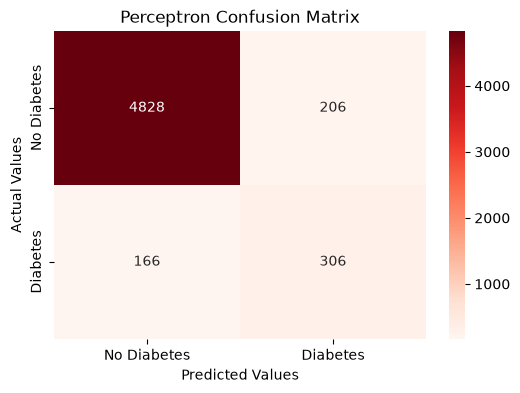

In [12]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Perceptron Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

## Conclusion:

The Perceptron classification algorithm was successfully implemented on the diabetes prediction dataset. The dataset was preprocessed using StandardScaler and OneHotEncoder. The data was divided into 80% training and 20% testing sets. The Perceptron classifier was trained to predict whether an individual has diabetes or not. The model performance was evaluated using accuracy, confusion matrix, precision, recall and F1-score.